# Orthogonal Factor Model Plots

These charts use the predictions and model-selection results generated by `Modell.py`. The training window ends before validation starts; model transformations and factor choices are kept fixed in the validation and test periods.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_FILE = "orthogonal_factor_model_predictions.csv"
PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "adatok" / DATA_FILE).exists()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"Could not find adatok/{DATA_FILE} from {Path.cwd()}")

DATA_DIR = PROJECT_DIR / "adatok"
predictions = pd.read_csv(DATA_DIR / DATA_FILE, parse_dates=["Date"])
summary = pd.read_csv(DATA_DIR / "orthogonal_factor_model_summary.csv")
steps = pd.read_csv(DATA_DIR / "orthogonal_factor_model_steps.csv")

TARGET = "AAPL"
if TARGET not in predictions["Target"].unique():
    TARGET = predictions["Target"].iloc[0]

print(f"Loaded {len(predictions):,} predictions for {summary['Target'].nunique()} targets.")
print(f"Selected ticker for prediction charts: {TARGET}")
print(f"Date range: {predictions['Date'].min():%Y-%m-%d} to {predictions['Date'].max():%Y-%m-%d}")

Loaded 270,900 predictions for 100 targets.
Selected ticker for prediction charts: AAPL
Date range: 2016-01-05 to 2026-10-13


## Factor Selection

The first chart shows the total model size, including the five fixed macro factors. The second ranks thematic factors by how often the stepwise procedure selected them.

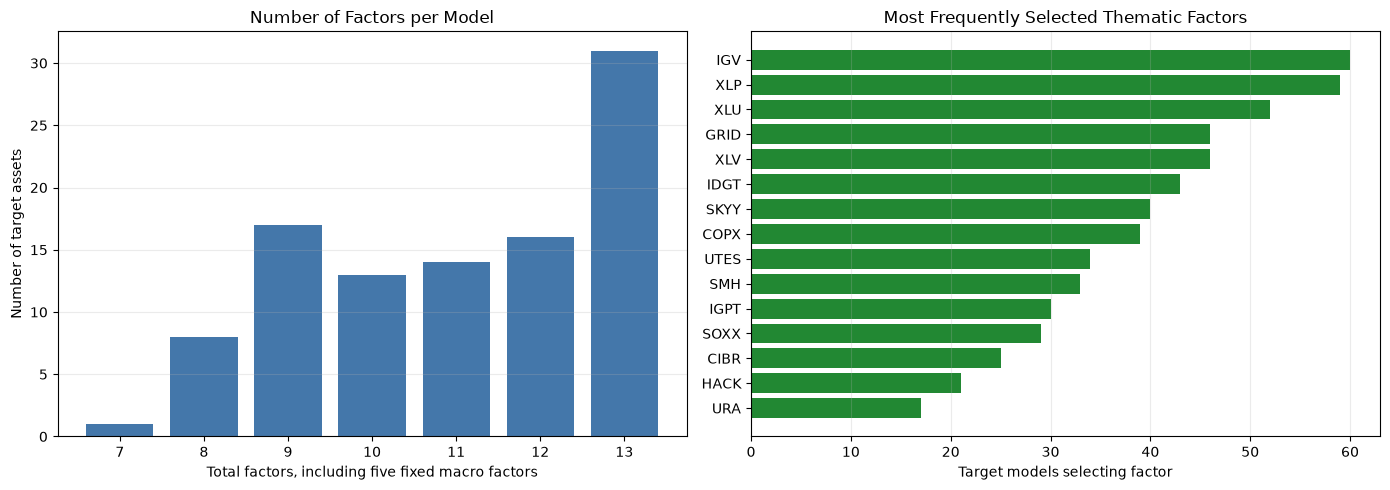

In [2]:
selected_steps = steps.loc[steps["Factor_Type"] == "Selected thematic"]
factor_frequency = selected_steps["Factor"].value_counts().head(15).sort_values()
model_sizes = summary["Total_Factor_Count"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(model_sizes.index.astype(str), model_sizes.values, color="#4477AA")
axes[0].set_title("Number of Factors per Model")
axes[0].set_xlabel("Total factors, including five fixed macro factors")
axes[0].set_ylabel("Number of target assets")
axes[0].grid(axis="y", alpha=0.25)

axes[1].barh(factor_frequency.index, factor_frequency.values, color="#228833")
axes[1].set_title("Most Frequently Selected Thematic Factors")
axes[1].set_xlabel("Target models selecting factor")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

## Prediction Performance

R² is measured relative to the target’s training-period mean. The scatter panels compare actual and predicted daily log returns; points closer to the diagonal indicate smaller prediction errors.

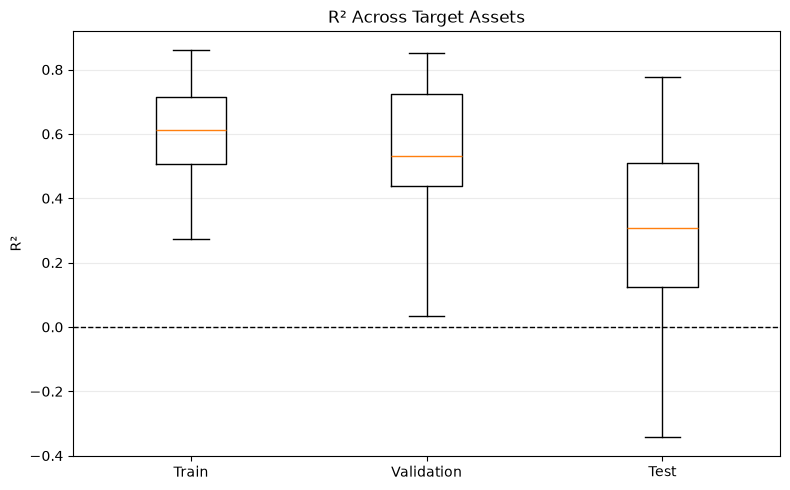

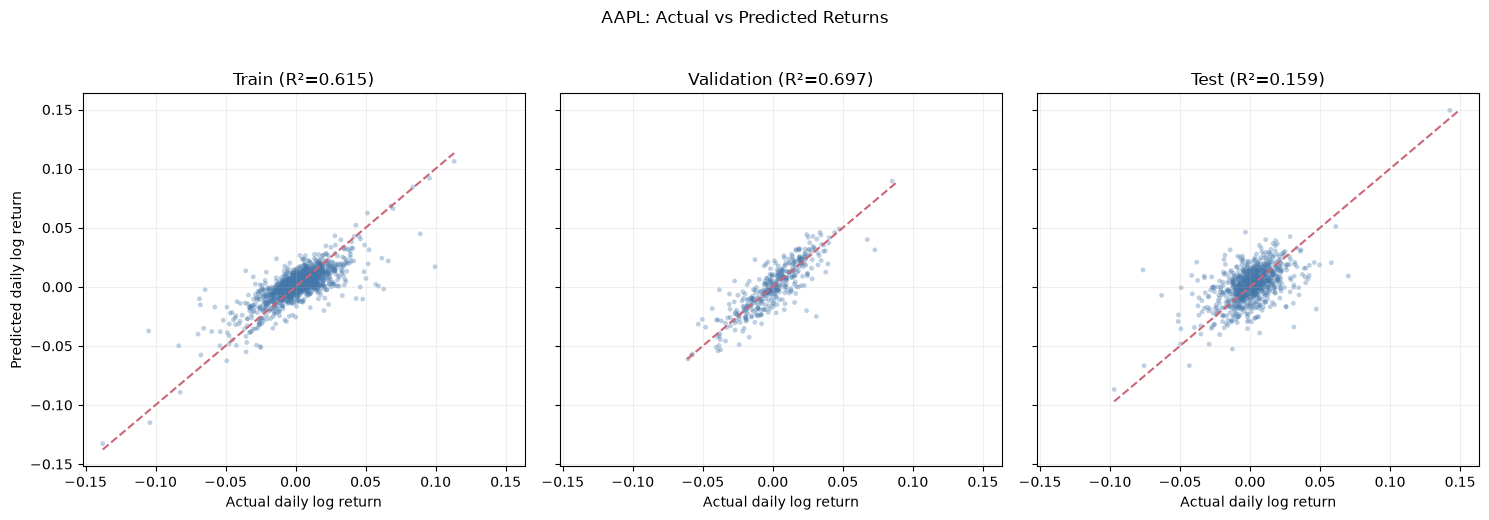

In [3]:
performance = summary[["Training_R2", "Validation_R2", "Test_R2"]].rename(
    columns={
        "Training_R2": "Train",
        "Validation_R2": "Validation",
        "Test_R2": "Test",
    }
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [performance[column].dropna() for column in performance.columns],
    tick_labels=performance.columns,
    showfliers=False,
)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_title("R² Across Target Assets")
ax.set_ylabel("R²")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

selected_summary = summary.set_index("Target").loc[TARGET]
target_predictions = predictions.loc[predictions["Target"] == TARGET]
split_order = ["Train", "Validation", "Test"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax, split in zip(axes, split_order):
    split_data = target_predictions.loc[target_predictions["Split"] == split]
    ax.scatter(
        split_data["Actual_Log_Return"],
        split_data["Predicted_Log_Return"],
        s=12,
        alpha=0.35,
        color="#4477AA",
        edgecolors="none",
    )
    if not split_data.empty:
        lower = min(split_data["Actual_Log_Return"].min(), split_data["Predicted_Log_Return"].min())
        upper = max(split_data["Actual_Log_Return"].max(), split_data["Predicted_Log_Return"].max())
        ax.plot([lower, upper], [lower, upper], color="#CC6677", linestyle="--")
    r2_column = {"Train": "Training_R2", "Validation": "Validation_R2", "Test": "Test_R2"}[split]
    ax.set_title(f"{split} (R²={selected_summary[r2_column]:.3f})")
    ax.set_xlabel("Actual daily log return")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Predicted daily log return")
fig.suptitle(f"{TARGET}: Actual vs Predicted Returns", y=1.03)
fig.tight_layout()
plt.show()

## Cumulative Returns

Daily log returns are accumulated and converted to cumulative simple returns. The predicted line compounds model conditional-mean predictions for illustration; it is not a tradable strategy backtest and excludes fees, slippage, and position sizing. Predictions in validation and test use the model fitted on training data, without refitting on those later periods.

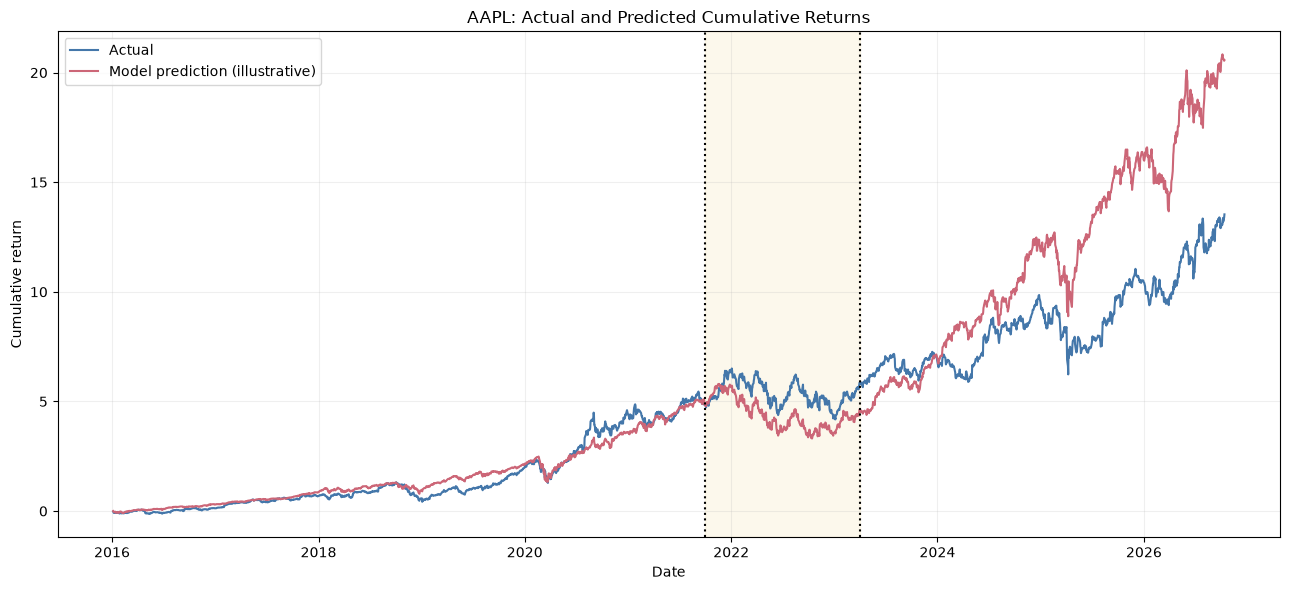

In [5]:
target_predictions = target_predictions.sort_values("Date").copy()
target_predictions["Actual_Cumulative_Return"] = np.expm1(
    target_predictions["Actual_Log_Return"].cumsum()
)
target_predictions["Predicted_Cumulative_Return"] = np.expm1(
    target_predictions["Predicted_Log_Return"].cumsum()
)

validation_start = pd.Timestamp("2021-10-01")
test_start = pd.Timestamp("2023-04-01")

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    target_predictions["Date"],
    target_predictions["Actual_Cumulative_Return"],
    label="Actual",
    color="#4477AA",
    linewidth=1.5,
)
ax.plot(
    target_predictions["Date"],
    target_predictions["Predicted_Cumulative_Return"],
    label="Model prediction (illustrative)",
    color="#CC6677",
    linewidth=1.5,
)
ax.axvline(validation_start, color="black", linestyle=":")
ax.axvline(test_start, color="black", linestyle=":")
ax.axvspan(validation_start, test_start, color="#EECC66", alpha=0.12)
ax.set_title(f"{TARGET}: Actual and Predicted Cumulative Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()